**<center style="font-size:4em;">Data exploration notebook</center>**

# To-Dos:
- speichern der Grafiken in einem Ordner mit einer bestimmten Namenskonvention um nicht unzählige Kopien zu haben

# Initialization

## Loading data

In [207]:
import pandas as pd

# Load the dataset
file_path = '../../data/raw/sickness_table.csv'

df = pd.read_csv(file_path, index_col=0)

In [208]:
df.dtypes

date         object
n_sick        int64
calls       float64
n_duty        int64
n_sby         int64
sby_need    float64
dafted      float64
dtype: object

## Initial data adaptions

In [209]:
# Convert date string column to datetime column
df['date'] = pd.to_datetime(df['date'])

# Add numeric date 
df['unix_ts_date'] = df['date'].astype(int) // 10**9

# Make date to index 
df.set_index('date', inplace=True)

# Correlation matrix of data

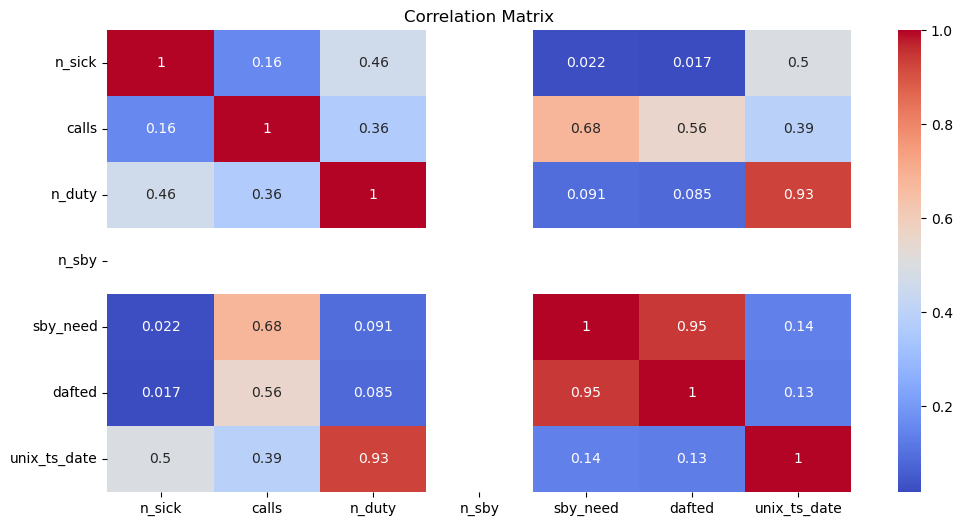

In [210]:
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

# Plot all columns over time

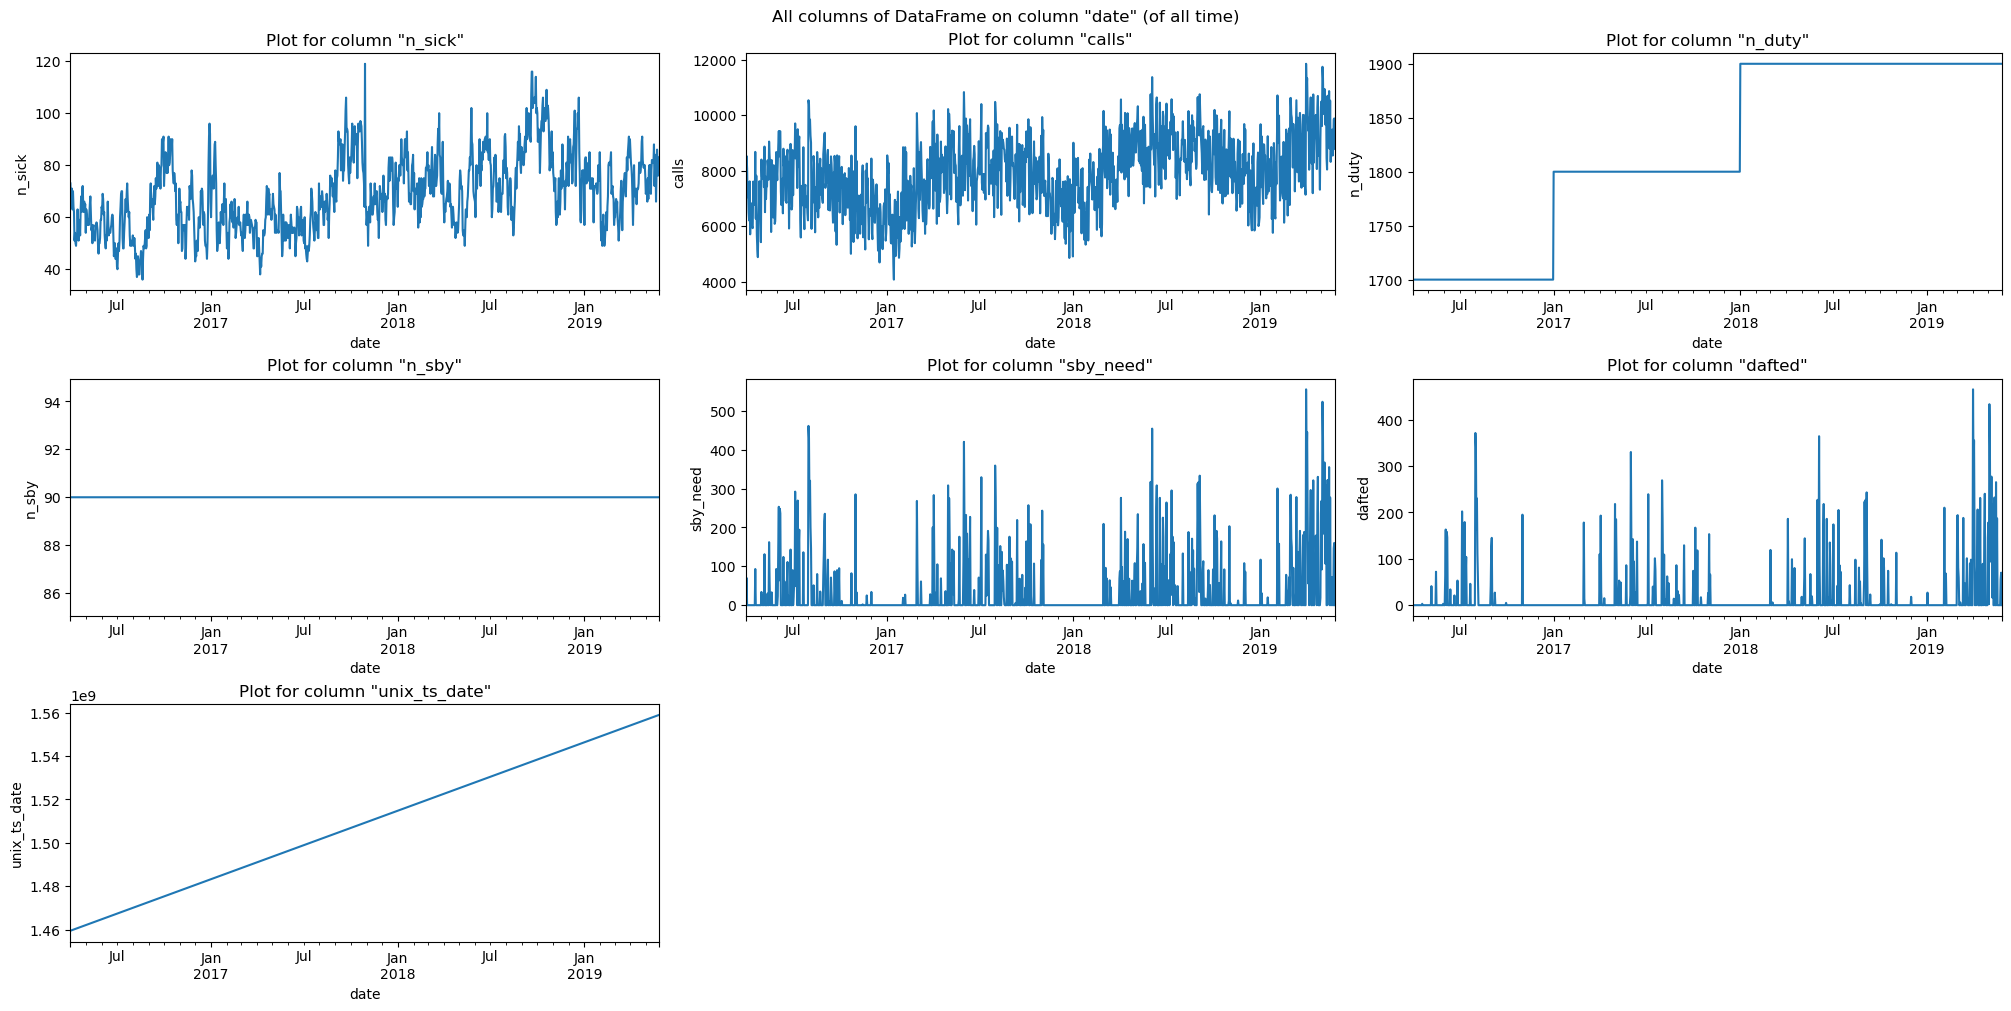

In [211]:
import math
import matplotlib.pyplot as plt
from typing import List, Optional

def plot_columns_on_index_in_subplots(df : pd.DataFrame, columns: Optional[List[str]] = None, annotation: str = "") -> None:

    if columns is None:
        columns = df.columns

    # number of columns in datafram
    num_columns = len(columns)

    # number of rows and columns for the subplots
    num_rows = math.ceil(math.sqrt(num_columns))
    num_cols = math.ceil(num_columns / num_rows)

    # Create subplots
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(20, 10), constrained_layout=True)
    fig.suptitle(f'All columns of DataFrame on column "{df.index.name}"' + (f" ({annotation})" if annotation else ""), fontsize=12)

    # Plots für jede Spalte erstellen
    for i, column in enumerate(columns):
        row = i // num_cols
        col = i % num_cols
        ax = axes[row, col]
        df[column].plot(ax=ax, title=f'Plot for column "{column}"')
        ax.set_xlabel(df.index.name)
        ax.set_ylabel(column)

    # Leere Subplots entfernen
    for j in range(i + 1, num_rows * num_cols):
        fig.delaxes(axes.flatten()[j])

    plt.show()

plot_columns_on_index_in_subplots(df, annotation="of all time")

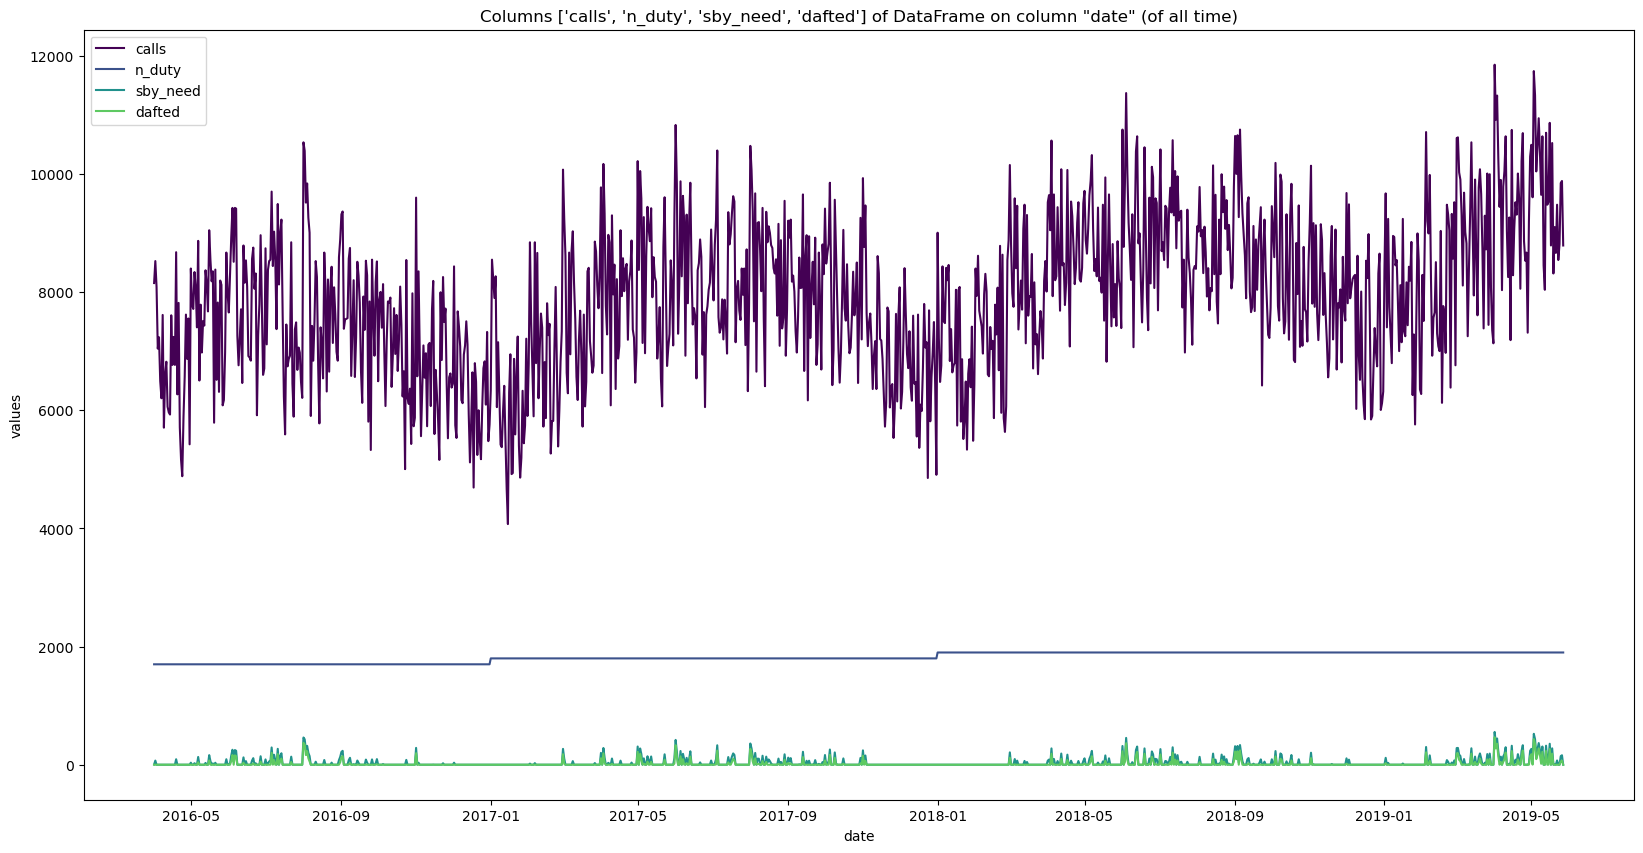

In [212]:
def plot_columns_on_index(df: pd.DataFrame, columns: Optional[List[str]] = None, annotation: str = "") -> None:
    if columns is None:
        columns = df.columns
    
    plt.figure(figsize=(20, 10))
    
    num_columns = len(columns)
    color_map = plt.get_cmap('viridis')
    
    for i, column in enumerate(columns):
        if column in df.columns:
            color = color_map(i / num_columns)
            plt.plot(df.index, df[column], label=column, color=color)
        else:
            print(f'Column "{column}" not found in DataFrame')
    
    plt.xlabel(df.index.name)
    plt.ylabel('values')
    plt.title(f'Columns {columns} of DataFrame on column "{df.index.name}"' + (f" ({annotation})" if annotation else ""))
    plt.legend()
    plt.show()

# Beispielaufruf der Funktion
plot_columns_on_index(df, columns=["calls", "n_duty", "sby_need", "dafted"], annotation="of all time")


## Plot columns over one year

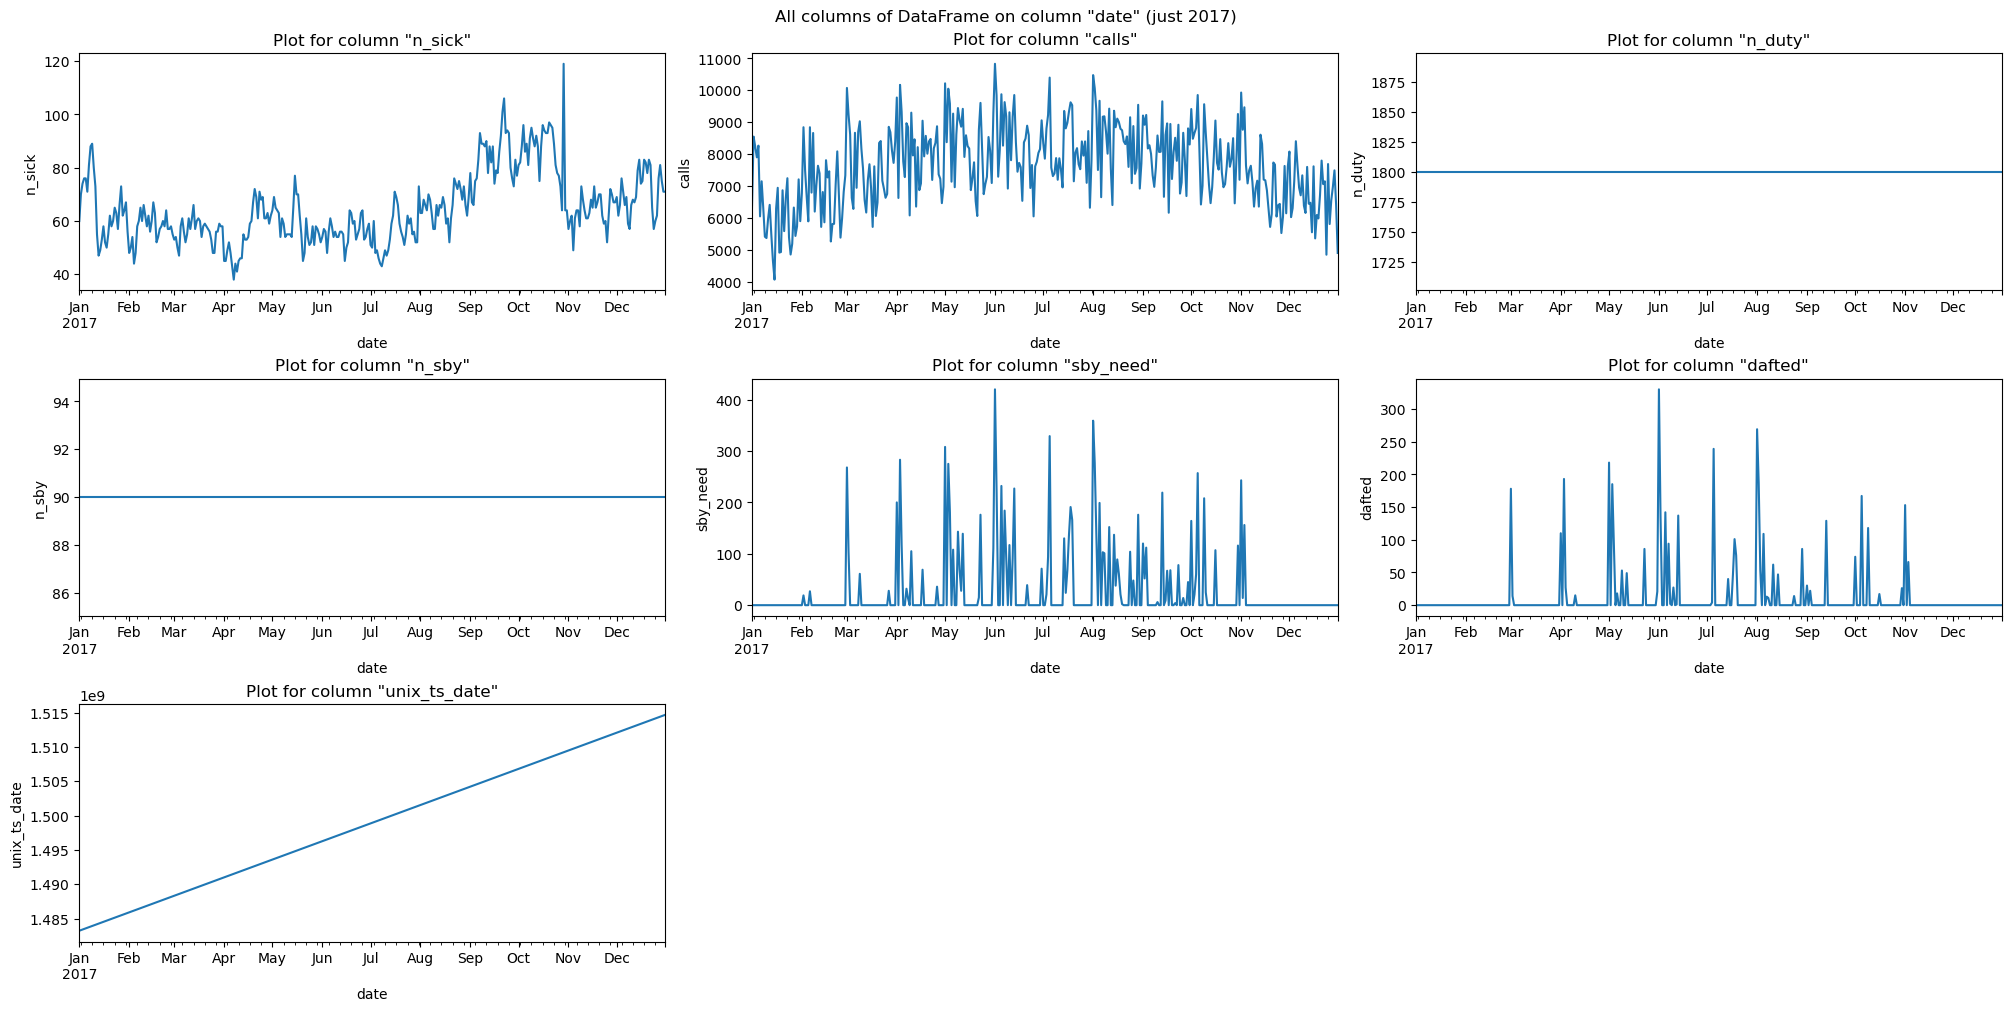

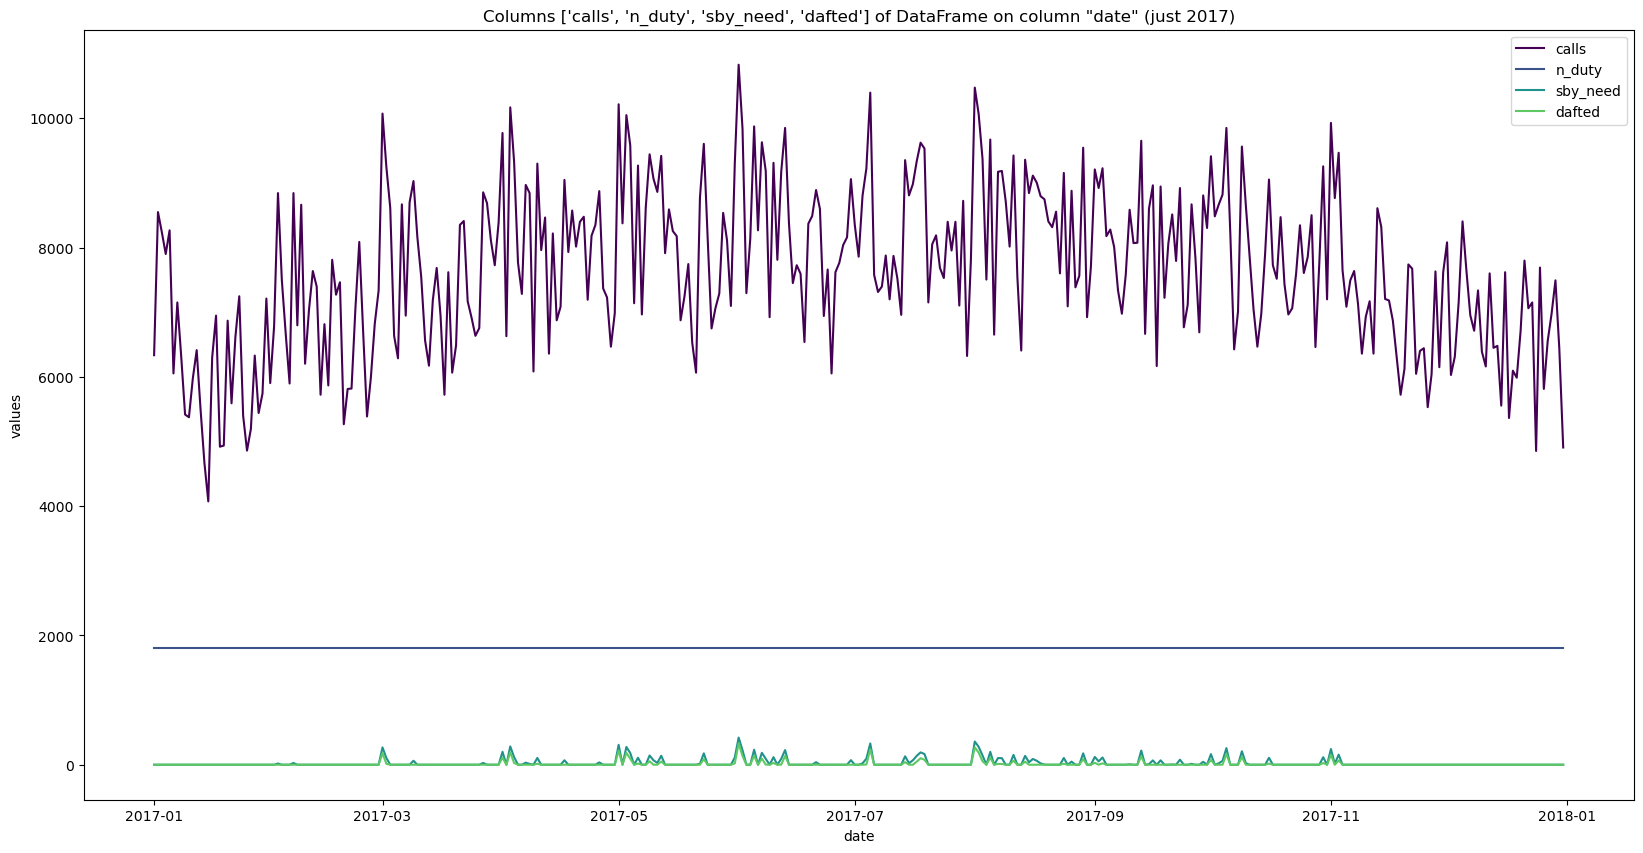

In [225]:
selected_year = 2017

one_year_df = df[df.index.year == selected_year]

plot_columns_on_index_in_subplots(one_year_df, annotation=f"just {selected_year}")
plot_columns_on_index(one_year_df, columns=["calls", "n_duty", "sby_need", "dafted"], annotation=f"just {selected_year}")

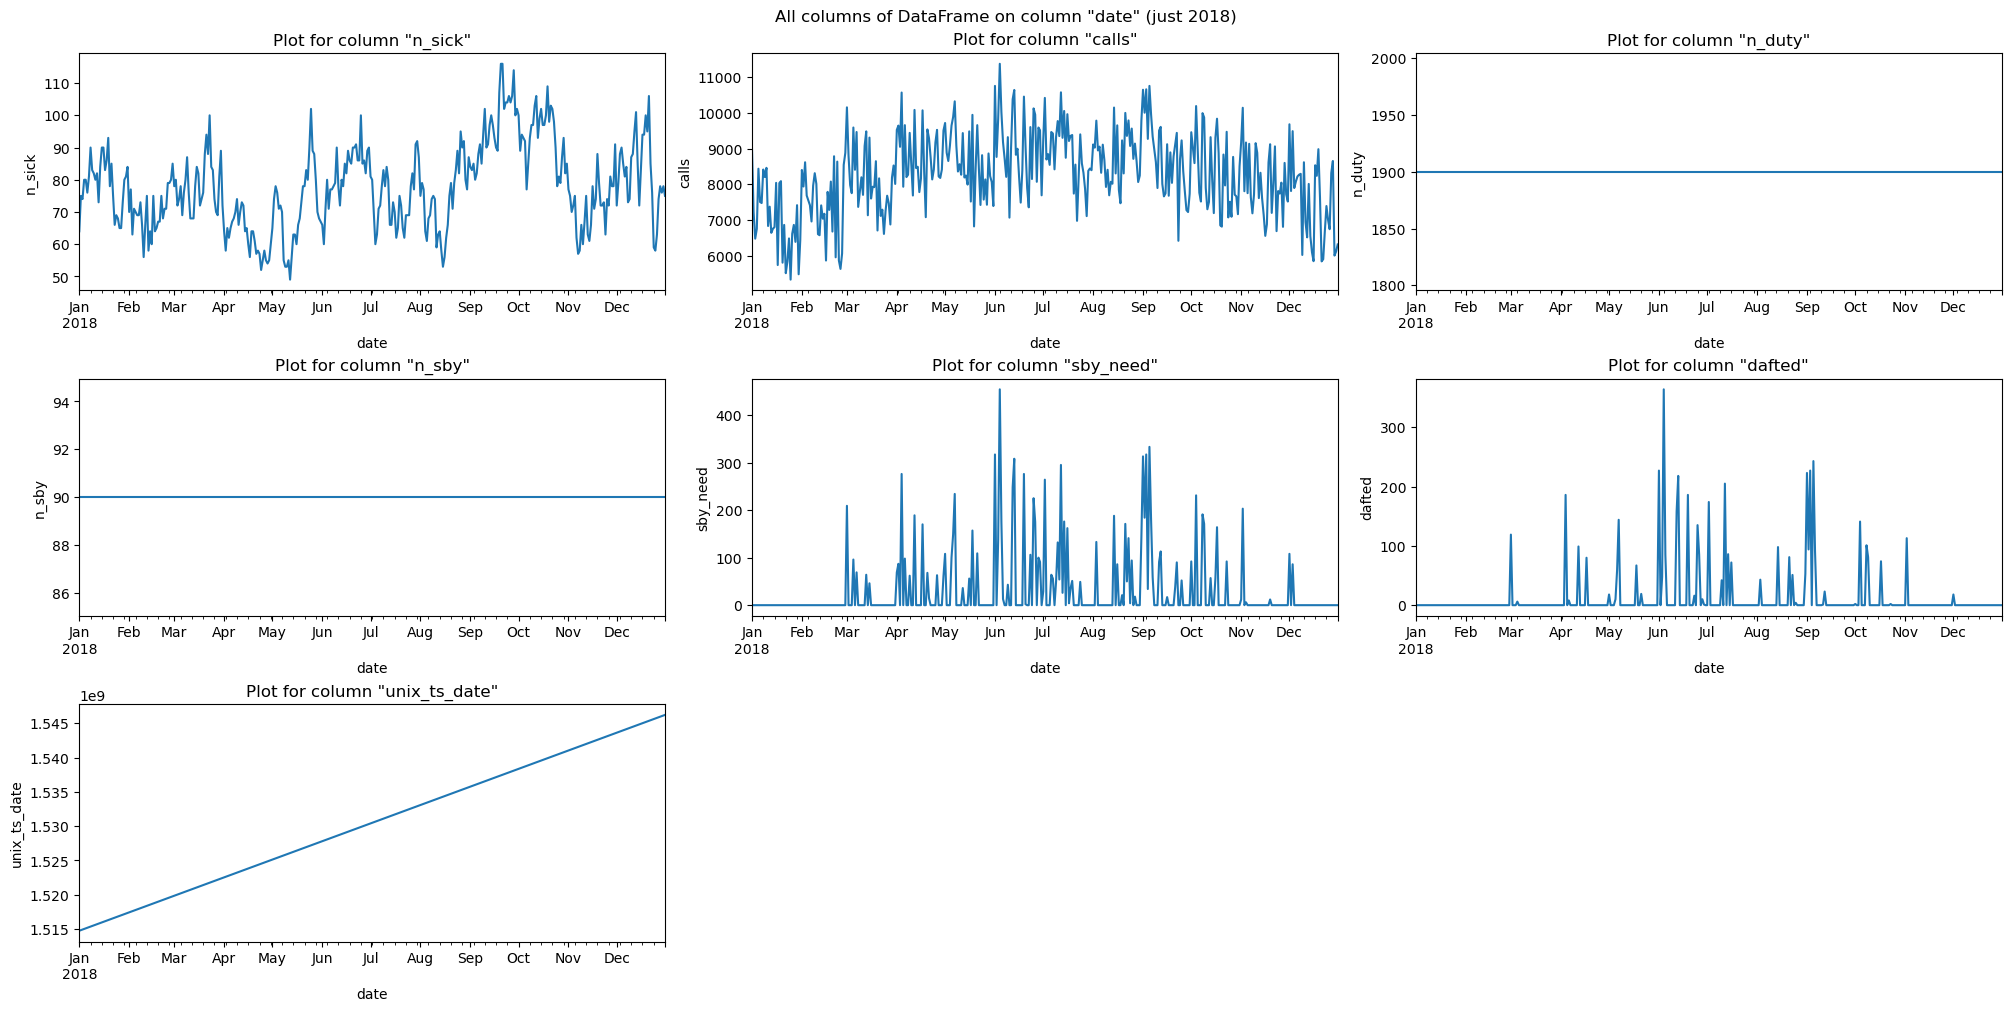

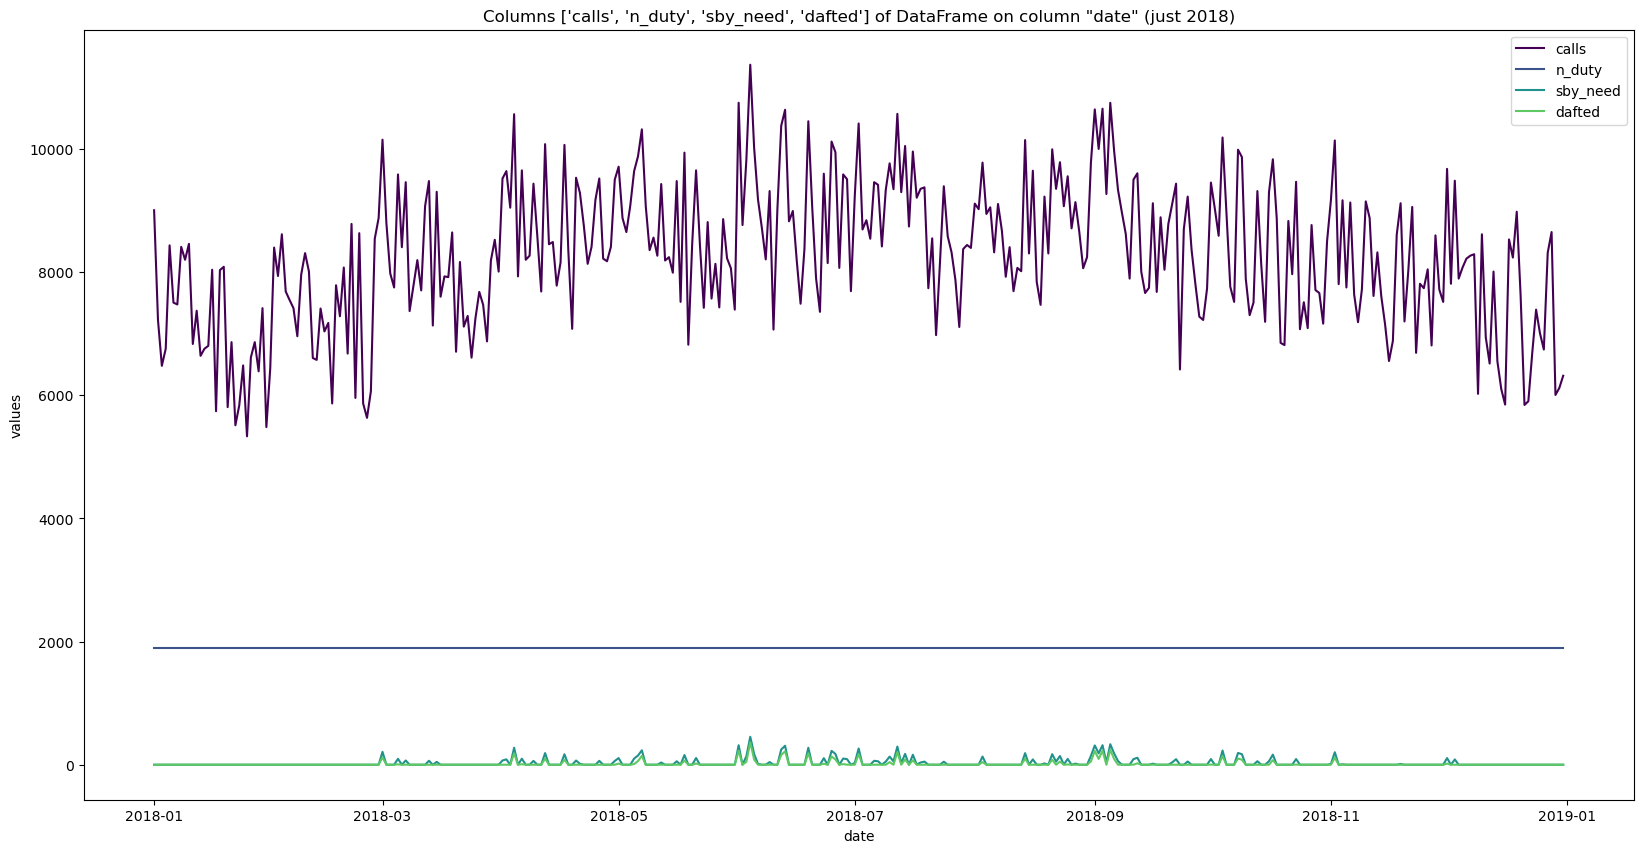

In [226]:
selected_year = 2018

one_year_df = df[df.index.year == selected_year]

plot_columns_on_index_in_subplots(one_year_df, annotation=f"just {selected_year}")
plot_columns_on_index(one_year_df, columns=["calls", "n_duty", "sby_need", "dafted"], annotation=f"just {selected_year}")

## Correlation matrix for one year

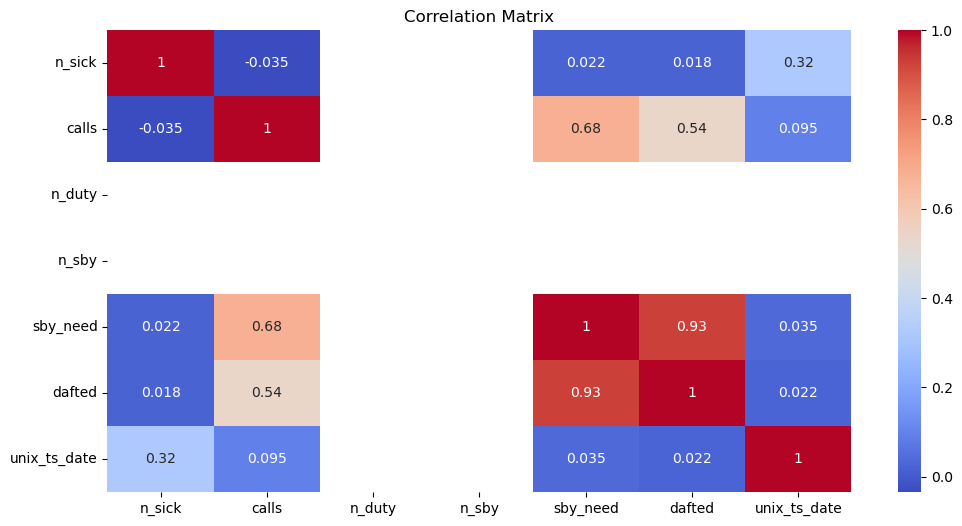

In [215]:
selected_year = 2018

one_year_df = df[df.index.year == selected_year]

plt.figure(figsize=(12, 6))
sns.heatmap(one_year_df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

## Findings

Erkenntnisse: 
- n_duty steigt am Anfang jeden Jahrs fix und wird nicht wieder gesenkt
- calls hat ein wiederkehrendes Muster. Es geht im Winter runter und beim Sommer hoch. Hat aber starke Ausschläge 
- ähnlich bei sby_need und logischerweise bei dafted. Im Winter nichts und sonst gelegengtlich

# Creating new columns from current columns

In [227]:
working_df = df.copy(deep=True)

# 
working_df["needed_personal"] = working_df.apply(lambda row: (row.sby_need + row.n_duty), axis=1)

working_df["personal_calculated_by_calls"] = working_df.apply(lambda row: (row.calls / 4.8), axis=1) 

##############

working_df["personal_calculated_by_calls_not_below_n_duty"] = working_df["personal_calculated_by_calls"]

# Filter from January to March
mask = (working_df["personal_calculated_by_calls"] < working_df["n_duty"])

# Add offset to filtered rows
working_df.loc[mask, 'personal_calculated_by_calls_not_below_n_duty'] = working_df.loc[mask, 'n_duty']

############

# 
working_df["sby_need_calculated_by_calls"] = working_df.apply(lambda row: row.personal_calculated_by_calls_not_below_n_duty - row.n_duty, axis=1)


#
working_df["calls_per_duty"] = working_df.apply(lambda row: row.calls / row.n_duty, axis=1)

#
working_df["call_stress"] = working_df.apply(lambda row: row.calls / (row.n_duty + row.sby_need), axis=1)

display(working_df.describe())

,n_sick,calls,n_duty,n_sby,sby_need,dafted,unix_ts_date,needed_personal,personal_calculated_by_calls,personal_calculated_by_calls_not_below_n_duty,sby_need_calculated_by_calls,calls_per_duty,call_stress
count,1152.000000,1152.000000,1152.000000,1152.0,1152.000000,1152.000000,1.152000e+03,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000
mean,68.808160,7919.531250,1820.572917,90.0,34.718750,16.335938,1.509192e+09,1855.291667,1649.902344,1857.789714,37.216797,4.347109,4.255659
std,14.293942,1290.063571,80.086953,0.0,79.694251,53.394089,2.874511e+07,117.992747,268.763244,120.808410,84.450859,0.663532,0.539535
min,36.000000,4074.000000,1700.000000,90.0,0.000000,0.000000,1.459469e+09,1700.000000,848.750000,1700.000000,0.000000,2.263333,2.263333
25%,58.000000,6978.000000,1800.000000,90.0,0.000000,0.000000,1.484330e+09,1800.000000,1453.750000,1800.000000,0.000000,3.875833,3.875833
50%,68.000000,7932.000000,1800.000000,90.0,0.000000,0.000000,1.509192e+09,1874.500000,1652.500000,1886.875000,0.000000,4.344298,4.344298
75%,78.000000,8827.500000,1900.000000,90.0,12.250000,0.000000,1.534054e+09,1900.000000,1839.062500,1900.000000,11.562500,4.831625,4.778991
max,119.000000,11850.000000,1900.000000,90.0,555.000000,465.000000,1.558915e+09,2455.000000,2468.750000,2468.750000,568.750000,6.236842,4.896288


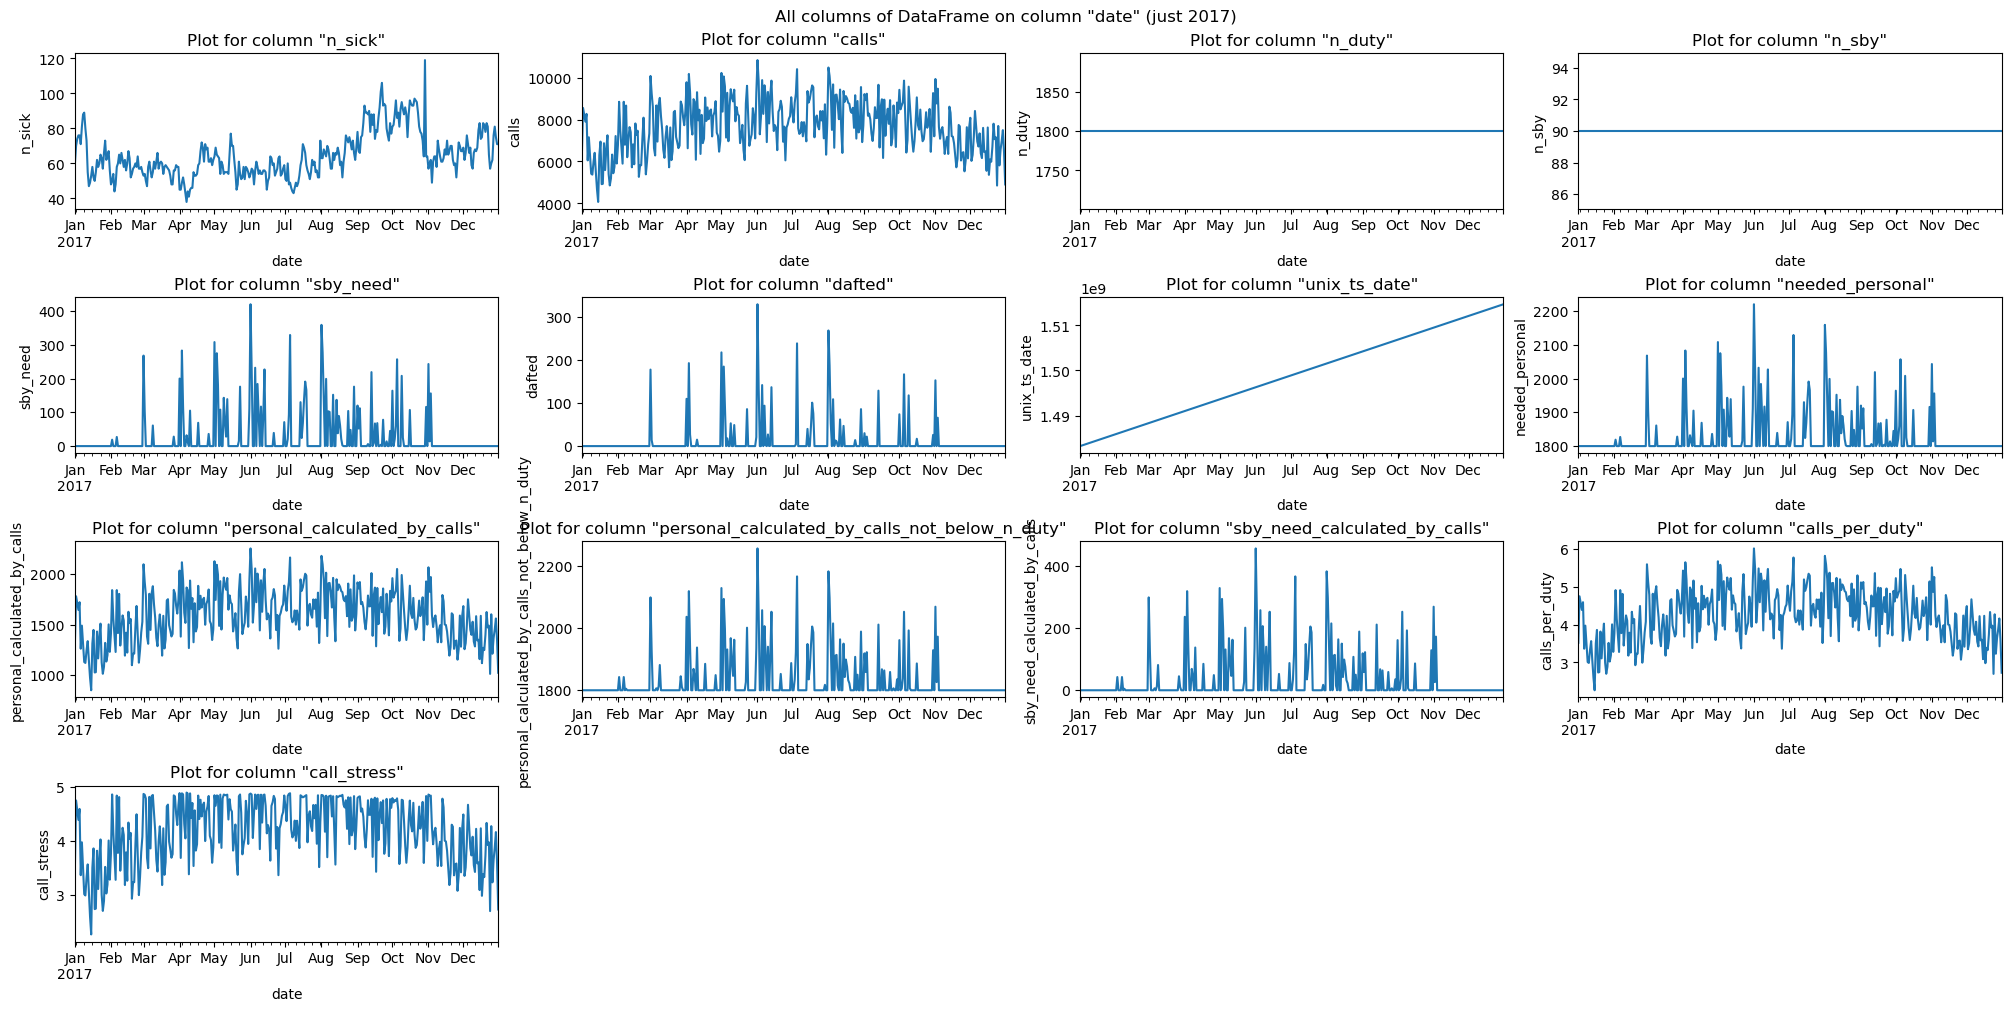

In [217]:
selected_year = 2017

one_year_df = working_df[working_df.index.year == selected_year]

plot_columns_on_index_in_subplots(one_year_df, annotation=f"just {selected_year}")

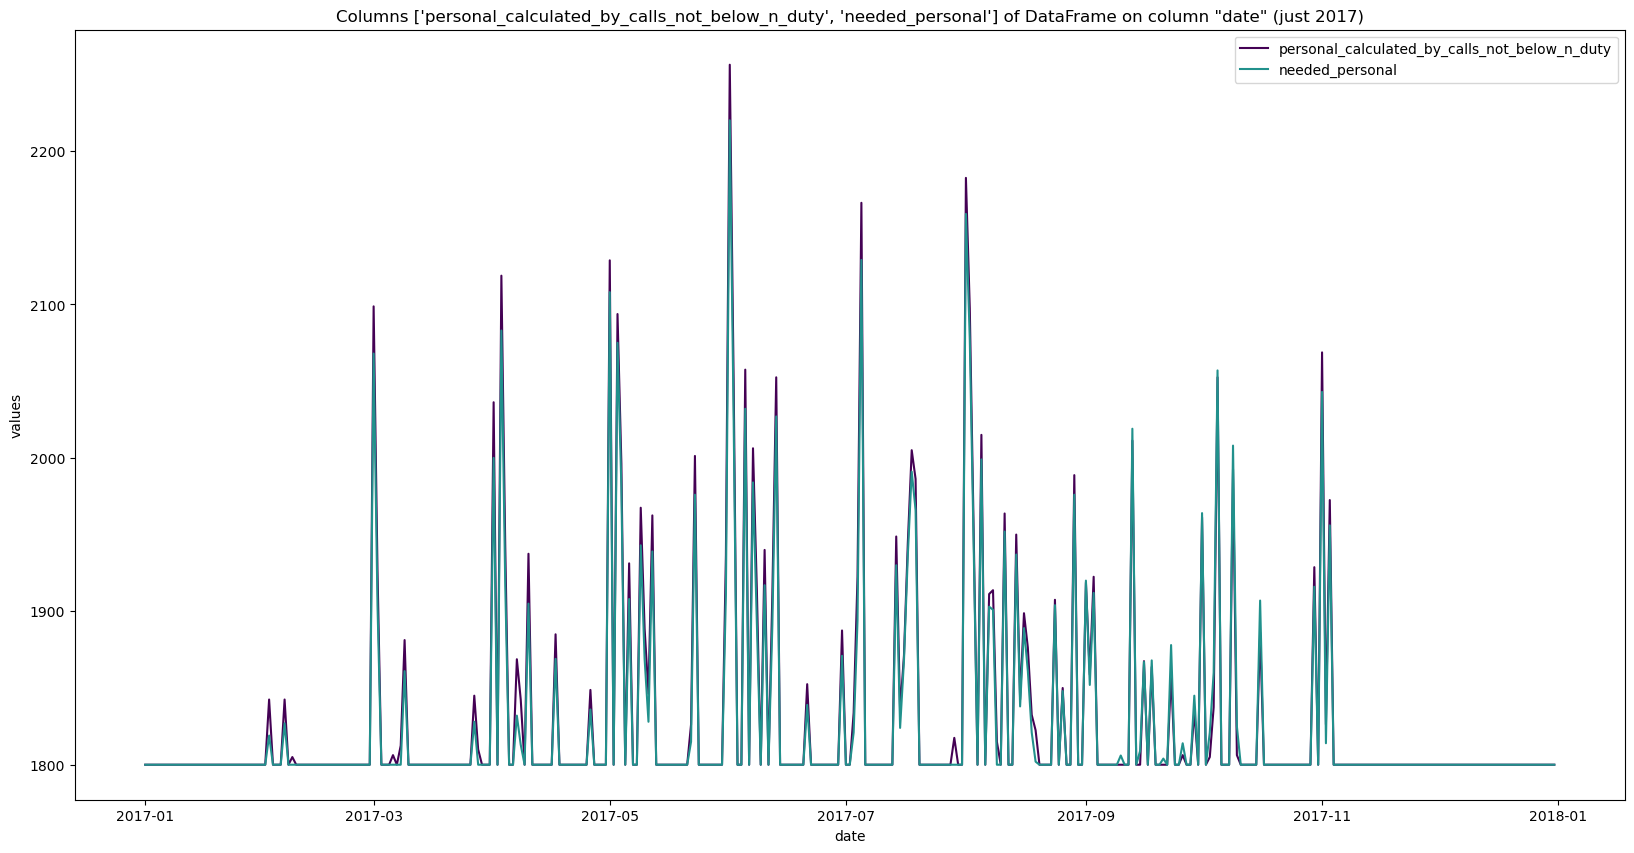

In [218]:
plot_columns_on_index(one_year_df, columns=["personal_calculated_by_calls_not_below_n_duty", "needed_personal"], annotation=f"just {selected_year}")

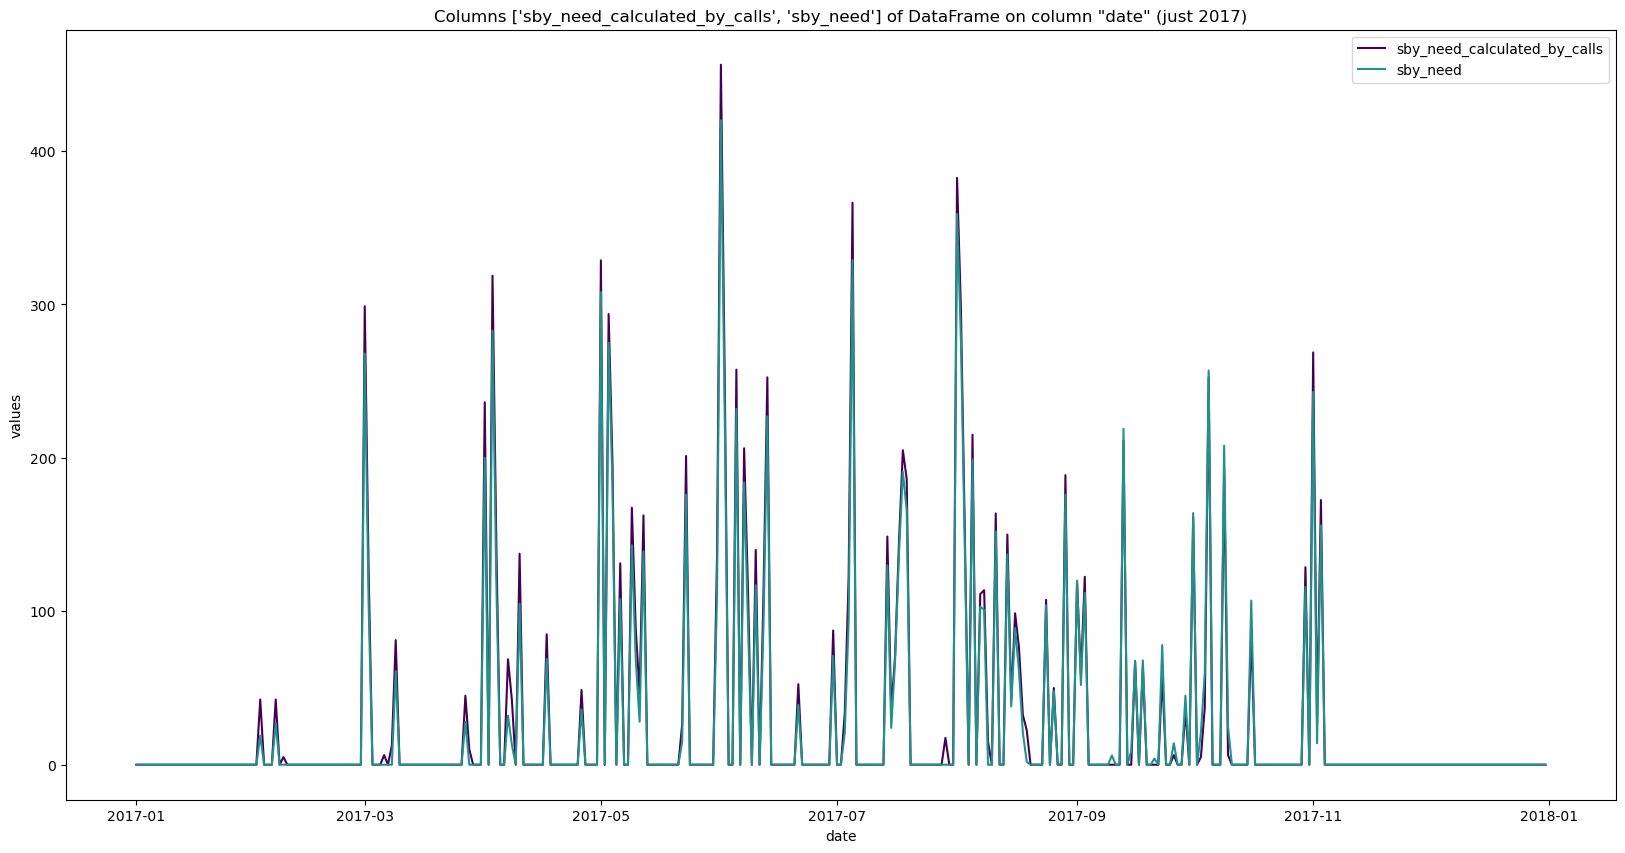

In [219]:
plot_columns_on_index(one_year_df, columns=["sby_need_calculated_by_calls", "sby_need"], annotation=f"just {selected_year}")

## Calculate metrics

In [229]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error


def calculate_regression_metrics(y_test : List, y_pred : List, print_results : bool = False) -> dict:
    results= {
        'MAE': float(mean_absolute_error(y_test, y_pred)),
        'MSE': float(mean_squared_error(y_test, y_pred)),
        'R2':float( r2_score(y_test, y_pred)),
        'MAPE': float(mean_absolute_percentage_error(y_test, y_pred)),
    }

    if print_results:
        print(f'Results: - ' + ', '.join(f'{key}: {value}' for key, value in results.items()))

    return results

print("For needed_personal over all time:")
calculate_regression_metrics(working_df["needed_personal"], working_df["personal_calculated_by_calls_not_below_n_duty"], print_results=True)

print("For sby_need over all time:")
_ = calculate_regression_metrics(working_df["sby_need"], working_df["sby_need_calculated_by_calls"], print_results=True)

For needed_personal over all time:
Results: - MAE: 3.738498263888889, MSE: 72.18950737847223, R2: 0.9948103196819081, MAPE: 0.0019167735471600801
For sby_need over all time:
Results: - MAE: 3.738498263888889, MSE: 72.18950737847223, R2: 0.9886237992741889, MAPE: 576632764789191.1


## Findings

Erkenntnisse:
- das benötigte Personal bzw die Einsatzfahrer im Bereitschaftsdienst kann man problemlos über calls berechnen und das mit einem guten R2-Score

To-Do:
- wie bekommt man calls gut predcitet

# Plot calls

## Plot over months

In [221]:
selected_year = 2017

monthly_df = df.copy(deep=True)[df.index.year == selected_year]

target_column_name = "calls"


# New column for each month 
for month in range(1, 13):
    monthly_df[f'month_{month}'] = monthly_df.apply(lambda row: row[target_column_name] if row.name.month == month else None, axis=1)

# Only select monthly columns
monthly_df = monthly_df[[f'month_{month}' for month in range(1, 13)]]

monthly_df.index = monthly_df.index.day

display(monthly_df)
display(monthly_df.describe())

,month_1,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12
date,,,,,,,,,,,,
1,6336.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,8550.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,8238.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,7902.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,8268.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
27,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6558.0
28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6978.0
29,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7494.0


,month_1,month_2,month_3,month_4,month_5,month_6,month_7,month_8,month_9,month_10,month_11,month_12
count,31.000000,28.000000,31.000000,30.000000,31.000000,30.000000,31.000000,31.000000,30.00000,31.000000,30.000000,31.000000
mean,6185.806452,6910.928571,7625.612903,8007.400000,8228.129032,8316.000000,8172.193548,8491.161290,8072.40000,7942.451613,7186.600000,6703.354839
std,1122.510562,998.717916,1090.230363,1048.536734,1112.122887,1098.626729,929.351366,1026.315062,887.55618,942.898893,1069.598977,891.576190
min,4074.000000,5268.000000,5724.000000,6084.000000,6066.000000,6054.000000,6324.000000,6408.000000,6168.00000,6426.000000,5532.000000,4854.000000
25%,5409.000000,5970.000000,6696.000000,7203.000000,7191.000000,7630.500000,7527.000000,7584.000000,7399.50000,7131.000000,6360.000000,6129.000000
50%,6054.000000,6819.000000,7620.000000,8100.000000,8256.000000,8214.000000,7956.000000,8748.000000,8127.00000,7854.000000,7149.000000,6714.000000
75%,6909.000000,7471.500000,8514.000000,8776.500000,9168.000000,9145.500000,8805.000000,9180.000000,8773.50000,8583.000000,7647.000000,7416.000000
max,8550.000000,8844.000000,10074.000000,10170.000000,10218.000000,10830.000000,10398.000000,10476.000000,9654.00000,9852.000000,9930.000000,8406.000000


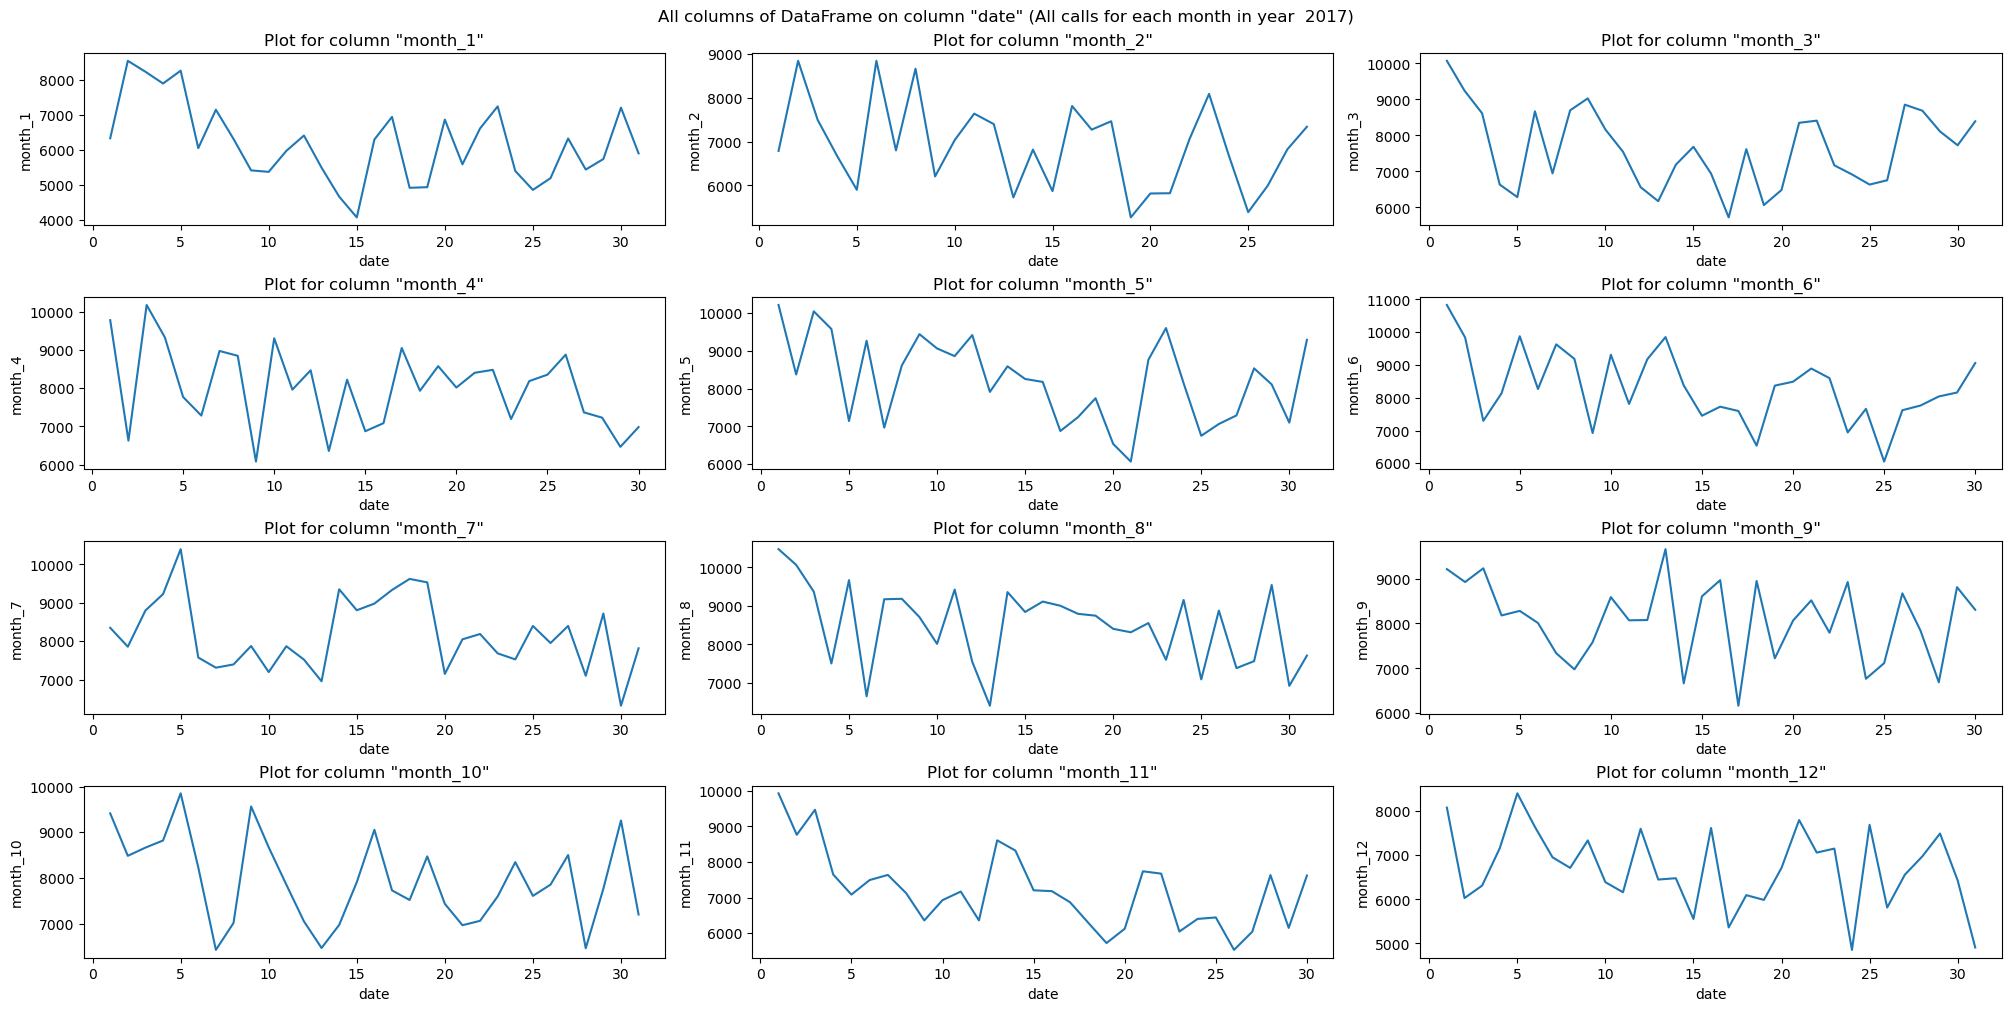

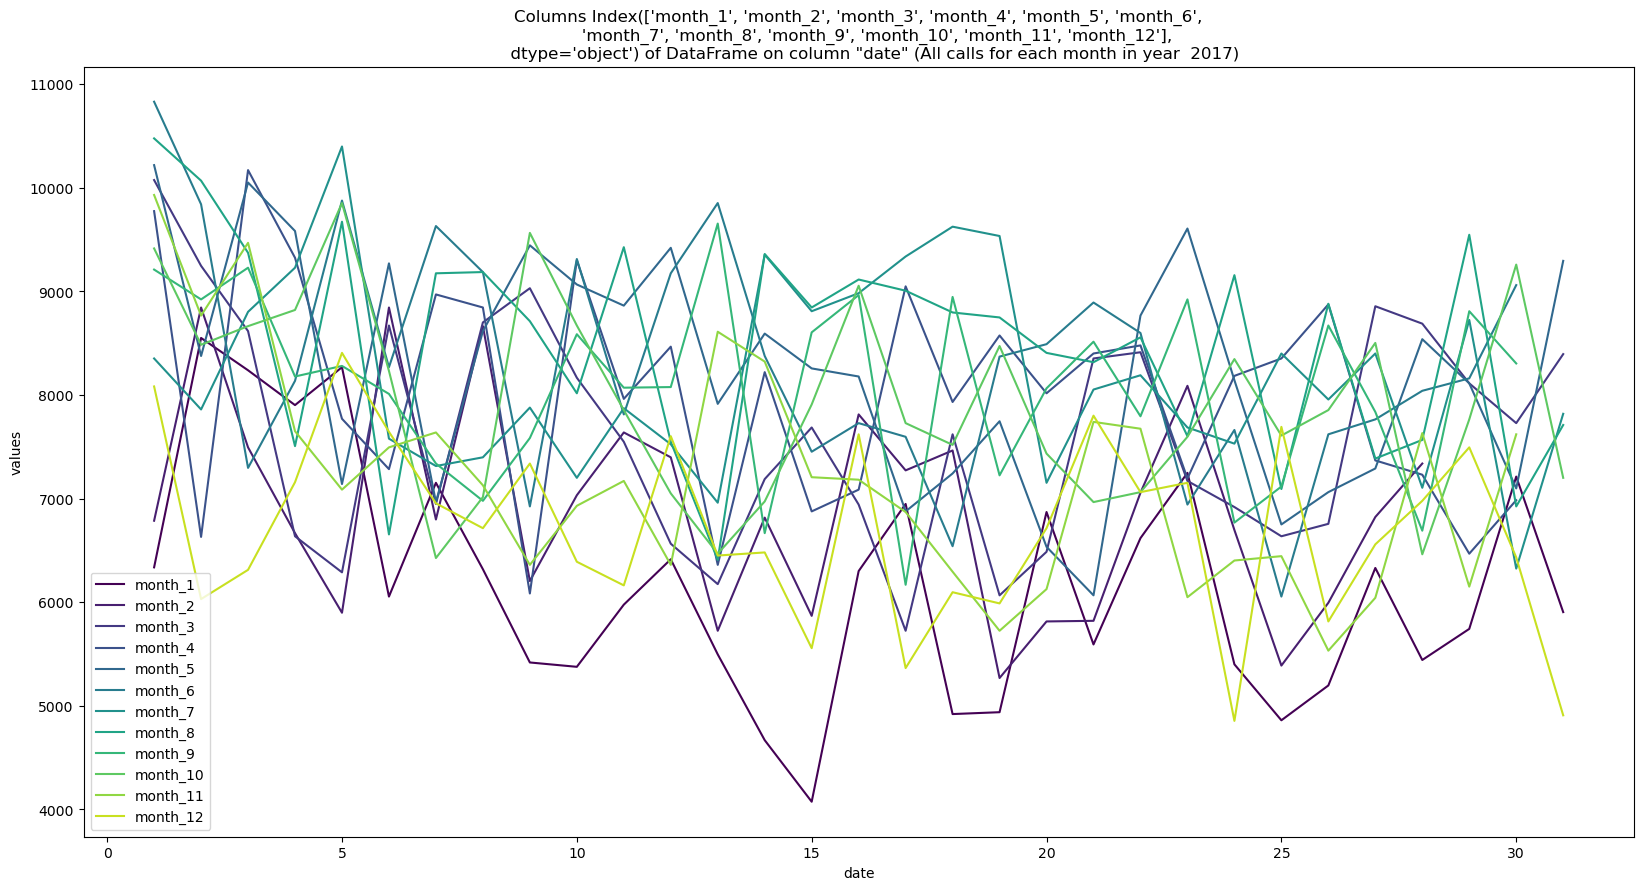

In [222]:
plot_columns_on_index_in_subplots(monthly_df, annotation=f"All calls for each month in year  {selected_year}")
plot_columns_on_index(monthly_df, annotation=f"All calls for each month in year  {selected_year}")

## Plot over weeks

In [223]:
selected_year = 2017

weekly_df = df.copy(deep=True)[df.index.year == selected_year]

target_column_name = "calls"

numer_of_weeks = 53


# New column for each month 
for week in range(1, numer_of_weeks):
    weekly_df[f'week_{week}'] = weekly_df.apply(lambda row: row[target_column_name] if row.name.isocalendar().week == week else None, axis=1)

# Only select monthly columns
weekly_df = weekly_df[[f'week_{week}' for week in range(1, numer_of_weeks)]]

weekly_df.index = weekly_df.index.dayofweek

display(weekly_df)
display(weekly_df.describe())

,week_1,week_2,week_3,week_4,week_5,week_6,week_7,week_8,week_9,week_10,...,week_43,week_44,week_45,week_46,week_47,week_48,week_49,week_50,week_51,week_52
date,,,,,,,,,,,,,,,,,,,,,
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6336.0
0,8550.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,8238.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,7902.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,8268.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6558.0
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6978.0
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7494.0


,week_1,week_2,week_3,week_4,week_5,week_6,week_7,week_8,week_9,week_10,...,week_43,week_44,week_45,week_46,week_47,week_48,week_49,week_50,week_51,week_52
count,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,...,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,7.000000,8.000000
mean,7497.428571,5346.000000,6026.571429,5745.428571,6972.000000,7511.142857,6603.428571,6408.000000,7860.000000,7946.571429,...,7733.142857,8479.714286,7011.428571,7172.571429,6566.571429,6838.285714,7229.142857,6462.000000,6523.714286,6526.500000
std,1000.638939,779.291986,874.003596,805.884784,1021.175793,964.473506,982.430805,934.132753,1455.656553,946.966887,...,662.390476,1157.314379,503.247738,1028.784859,834.545556,896.845902,660.712602,890.456063,966.737075,900.135704
min,6054.000000,4074.000000,4920.000000,4860.000000,5898.000000,6204.000000,5268.000000,5388.000000,6288.000000,6564.000000,...,6462.000000,7086.000000,6360.000000,5724.000000,5532.000000,6030.000000,6390.000000,5364.000000,4854.000000,4908.000000
25%,6735.000000,5022.000000,5265.000000,5298.000000,6285.000000,6915.000000,5796.000000,5817.000000,6729.000000,7248.000000,...,7602.000000,7425.000000,6645.000000,6582.000000,6087.000000,6096.000000,6834.000000,5859.000000,6042.000000,6205.500000
50%,7902.000000,5418.000000,6300.000000,5442.000000,6786.000000,7398.000000,6816.000000,5994.000000,7338.000000,8166.000000,...,7764.000000,8766.000000,7128.000000,7182.000000,6402.000000,6312.000000,7158.000000,6450.000000,6714.000000,6495.000000
75%,8253.000000,5736.000000,6744.000000,6036.000000,7353.000000,8151.000000,7368.000000,6876.000000,8931.000000,8685.000000,...,8100.000000,9363.000000,7332.000000,7764.000000,7059.000000,7626.000000,7491.000000,7041.000000,7107.000000,7107.000000
max,8550.000000,6414.000000,6948.000000,7248.000000,8844.000000,8844.000000,7812.000000,8088.000000,10074.000000,9030.000000,...,8502.000000,9930.000000,7638.000000,8610.000000,7740.000000,8082.000000,8406.000000,7620.000000,7800.000000,7692.000000


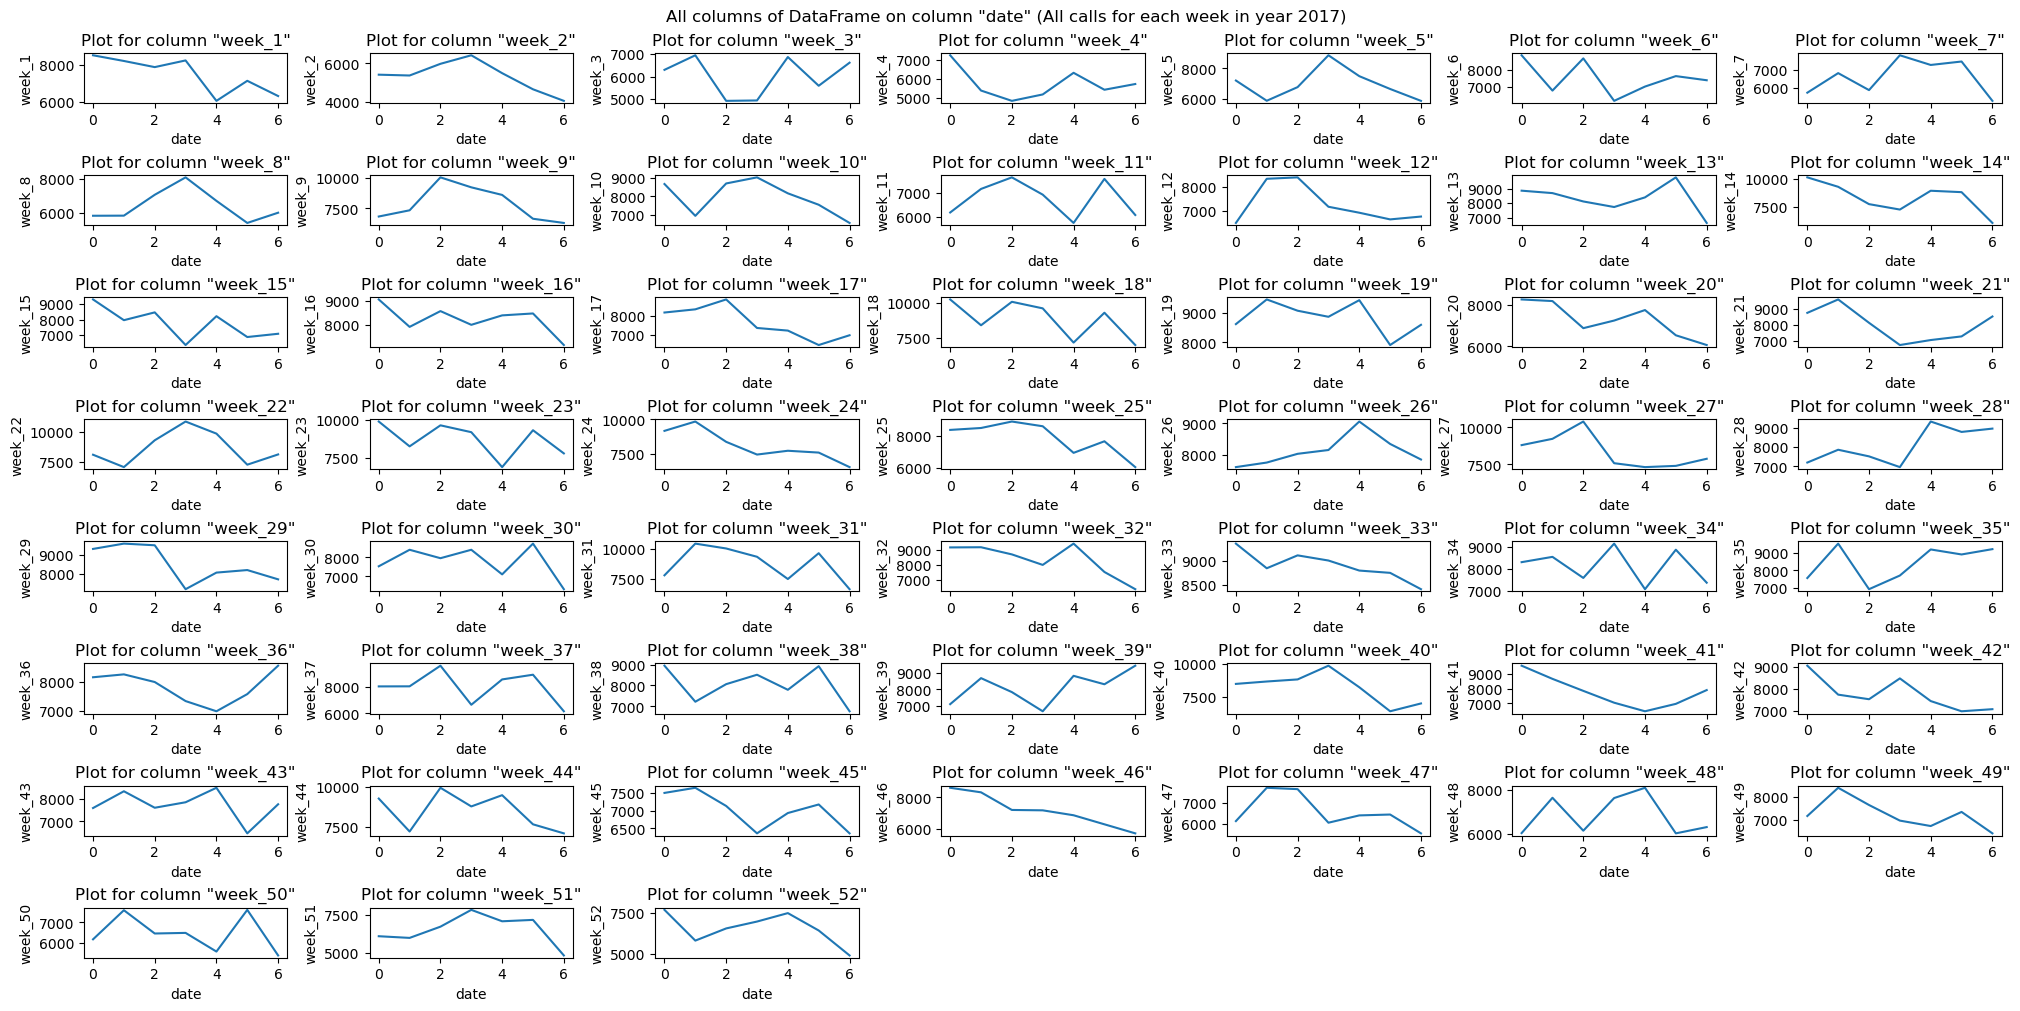

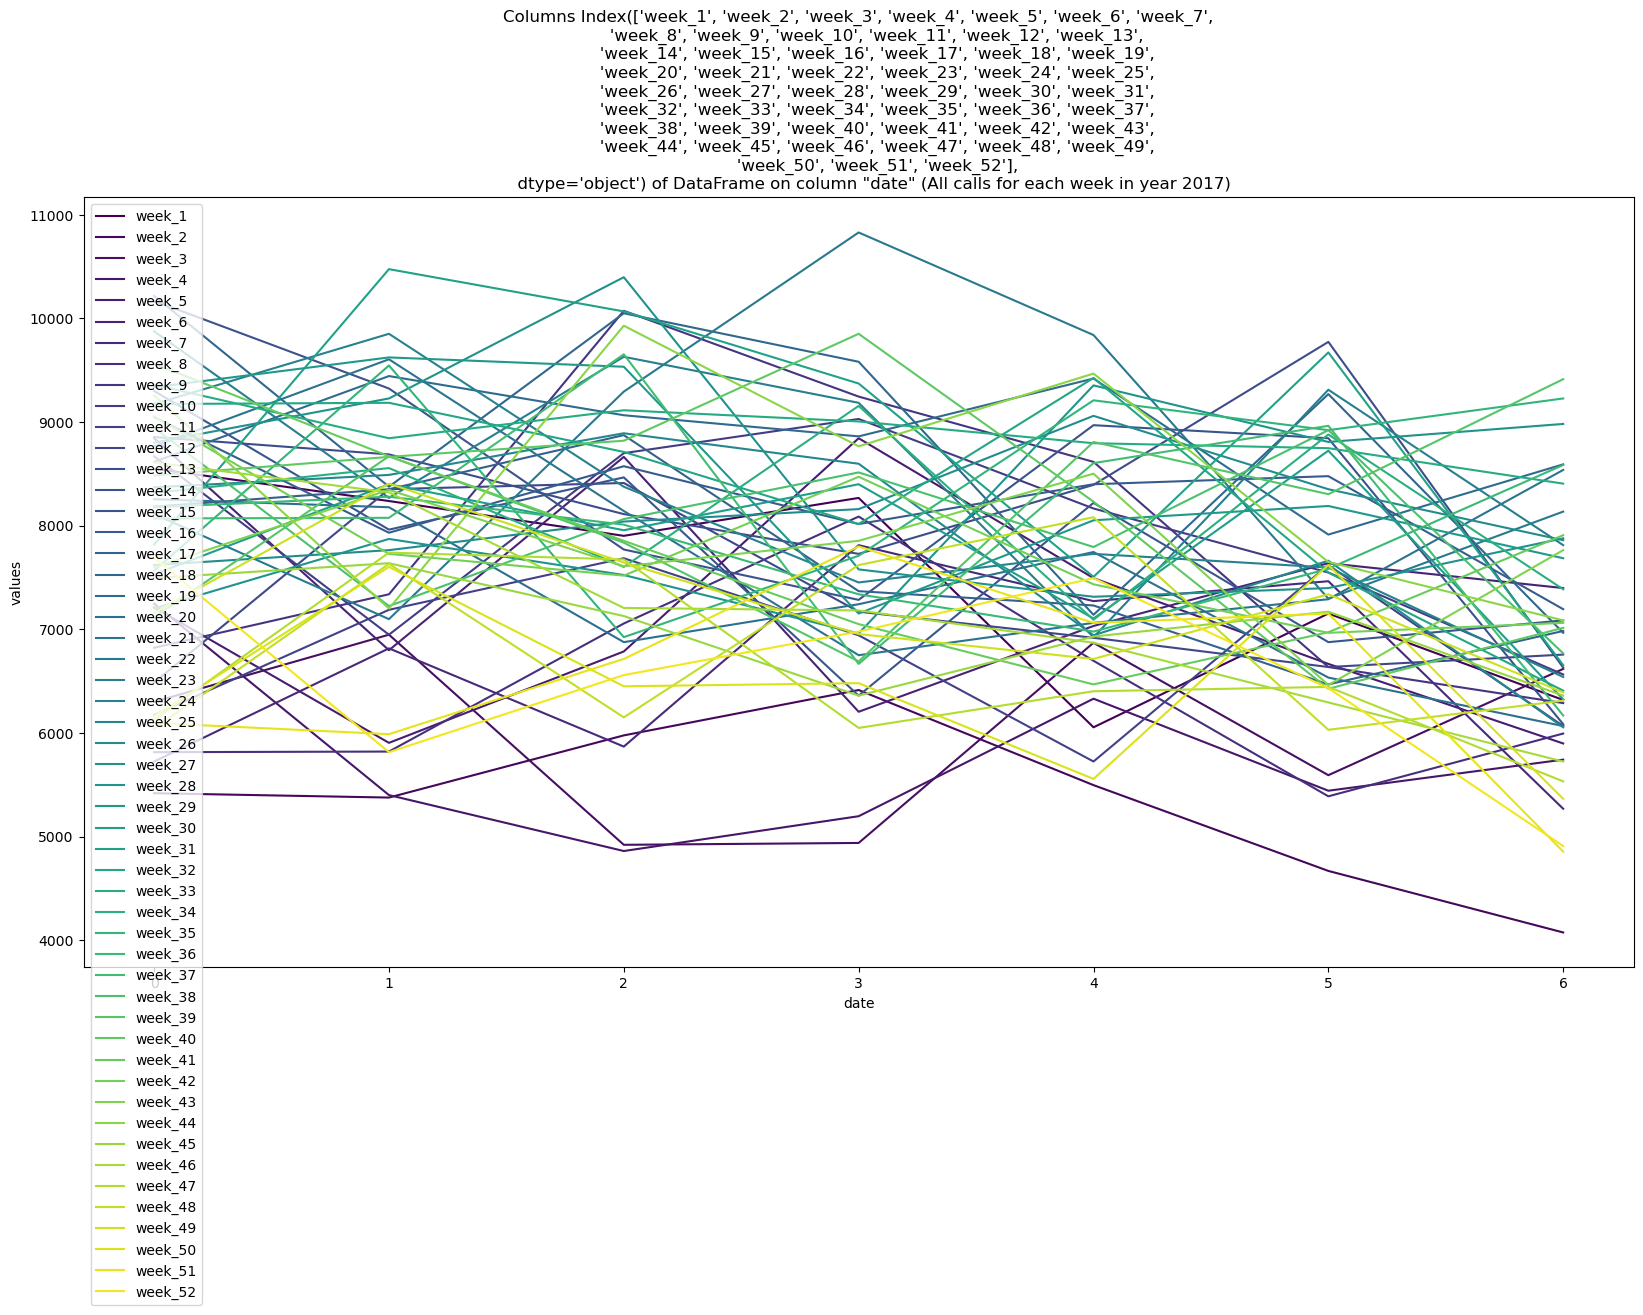

In [224]:
plot_columns_on_index_in_subplots(weekly_df, annotation=f"All calls for each week in year {selected_year}")
plot_columns_on_index(weekly_df, annotation=f"All calls for each week in year {selected_year}")